## Week 1 Tutorial for COfDSAI ##

Want to first import any relevant packages and files.

In [47]:
# necessary imports
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
from load_industries import load_industry_returns, estimation_inputs

In [48]:
# want to run the load_industries.py file to get the needed data
R = load_industry_returns("30_Industry_Portfolios.csv")
mu, Sigma, names = estimation_inputs(R, start="2015-01", end="2024-12")

#print(mu, Sigma, names)


Now we have the inputs, so we want to implement the convex problem.

First we define the variables which we will need.

In [49]:
n = len(mu)
weq = 1/n
weq_v = weq*np.ones(30)
#weq_v

sigma2 = weq_v.T @ Sigma @ weq_v
sigma2
volatilityeq = 100 * np.sqrt(weq_v @ Sigma @ weq_v)

print("The upper bound of our variance is:", sigma2*100, "%")
print("With a volatility of: ", volatilityeq, "%")

The upper bound of our variance is: 3.0154289808169934 %
With a volatility of:  17.364990586858934 %


Now we start with part A. We'll use the CVXPY package to implement this.


In [50]:
# have n variables w
w = cp.Variable(n)
proba = cp.Problem(cp.Maximize(mu @ w),
                    [
                        cp.sum(w) == 1,
                        w >= 0,
                        cp.quad_form(w, Sigma) <= sigma2,
                    ])

proba.solve()

wa = np.clip(w.value, 0, None)
wa = wa / wa.sum()

# get annual return and volatility (where volatility is the standard deviation)
returna = proba.value * 100
volatilitya = 100 * np.sqrt(wa @ Sigma @ wa)

# check if the solution is optimal
print("Status of solution: ", proba.status)
print("Expected Annual Return of Analyst's Portfolio: ", returna, "%")
print("Annual Volatility of Analyst's Portfolio: ", volatilitya, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if w.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * w.value[i], 2), "%") # print the weights of the invested stocks

Status of solution:  optimal
Expected Annual Return of Analyst's Portfolio:  19.232658942032668 %
Annual Volatility of Analyst's Portfolio:  17.364990598603864 %
Smoke 14.4 %
Util 6.38 %
Servs 17.3 %
BusEq 60.35 %
Meals 1.57 %


We see that the analyst's portfolio yields an expected return of 19.23%. We also see that the analysts portfolio is quite dense in its allocations. It assigns 60.35% to BusEq, which is quite a big investment in one stock.

Now we can do part B, where we will diversify the portfolio. I decide to diversify by taking the least related 15 stocks.

In [51]:
# make a new problem for the diversified portfolio
wmin = 0.01
wmax = 0.20
w2 = cp.Variable(n)
probb = cp.Problem(cp.Maximize(mu @ w2),
                    [
                        cp.sum(w2) == 1,
                        w2 >= wmin,
                        w2 <= wmax,
                        cp.quad_form(w2, Sigma) <= sigma2,
                    ])

probb.solve()

wb = np.clip(w2.value, 0, None)
wb = wb / wb.sum()

returnb = probb.value * 100
volatilityb = 100 * np.sqrt(wb @ Sigma @ wb)

# check if the solution is optimal
print("Status of solution: ", probb.status)
print("Expected Annual Return of Analyst's Portfolio: ", returnb, "%")
print("Annual Volatility of Analyst's Portfolio: ", volatilityb, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if w2.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * w2.value[i], 2), "%") # print the weights of the invested stocks

Status of solution:  optimal
Expected Annual Return of Analyst's Portfolio:  16.605910225550392 %
Annual Volatility of Analyst's Portfolio:  17.36499059715558 %
Food 1.0 %
Beer 1.0 %
Smoke 9.29 %
Games 1.0 %
Books 1.0 %
Hshld 1.0 %
Clths 1.0 %
Hlth 1.0 %
Chems 1.0 %
Txtls 1.0 %
Cnstr 1.0 %
Steel 1.0 %
FabPr 1.0 %
ElcEq 1.0 %
Autos 8.01 %
Carry 1.0 %
Mines 1.0 %
Coal 1.0 %
Oil 1.0 %
Util 1.0 %
Telcm 1.0 %
Servs 20.0 %
BusEq 20.0 %
Paper 1.0 %
Trans 1.0 %
Whlsl 1.0 %
Rtail 17.7 %
Meals 1.0 %
Fin 1.0 %
Other 1.0 %


Also try an approach where we reduce the amount of maximum variance (the w_eq' * Sigma * w_eq) to be 15% standard deviation (equals variance of sigma_bar^2 = 0.000225). So instead of limiting investment in stocks directly, we just state we want a less risky portfolio.

In [52]:
# make a new problem for the diversified portfolio
sigma2_max = 0.0225
w3 = cp.Variable(n)
probb2 = cp.Problem(cp.Maximize(mu @ w3),
                    [
                        cp.sum(w3) == 1,
                        w3 >= 0,
                        cp.quad_form(w3, Sigma) <= sigma2_max,
                    ])

probb2.solve()

wb2 = np.clip(w3.value, 0, None)
wb2 = wb2 / wb2.sum()

returnb2 = probb2.value * 100
volatilityb2 = 100 * np.sqrt(wb2 @ Sigma @ wb2)

# check if the solution is optimal
print("Status of solution: ", probb2.status)
print("Expected Annual Return of My Portfolio: ", returnb2, "%")
print("Annual Volatility of My Portfolio: ", volatilityb2, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if w3.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * w3.value[i], 2), "%") # print the weights of the invested stocks

Status of solution:  optimal
Expected Annual Return of My Portfolio:  16.219439867795803 %
Annual Volatility of My Portfolio:  15.00000004091746 %
Beer 2.13 %
Smoke 15.09 %
Util 21.28 %
Servs 24.02 %
BusEq 33.58 %
Rtail 0.86 %
Meals 3.03 %


Now we see that reducing the maximum variance directly still yields an optimal solution, thus we can continue with this.
The diversification decided on is the limiting of the variance to make the solver invest "less riskily" on it's own.
Now we look at part c, how the fiversification influences the expected annual return.


0.014058322236002122  and optimal


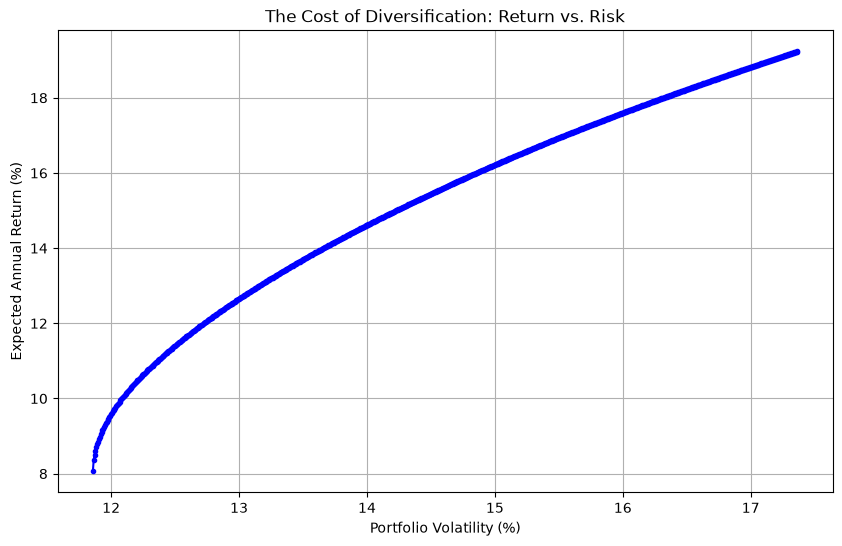

In [53]:
# first have to find the minimum variance possible to find lower bound of our variance evaluation
wminvar = cp.Variable(n)
probminvar = cp.Problem(cp.Minimize(cp.quad_form(wminvar, Sigma)), 
                         [
                            cp.sum(wminvar) == 1, 
                            wminvar >= 0,
                         ])

probminvar.solve()
minvar = probminvar.value
print(minvar, " and", probminvar.status)

# make a range of variances from the lower bound we find to the maximum (the analyst's portfolio)
variancebound = np.linspace(minvar, sigma2, 1000)

# initialise the arrays that'll hold the expect returns and volatilities
expectedreturns = []
volatilities = []

wall = cp.Variable(n)
# found out you can use a cvxpy parameter in for loops instead of redefining problem x (1000) times
param = cp.Parameter(nonneg=True)
probc = cp.Problem(cp.Maximize(mu @ wall),
                    [
                        cp.sum(wall) == 1,
                        wall >= 0, 
                        cp.quad_form(wall, Sigma) <= param
                    ])

# for loop through the variances we chose
for limit in variancebound:
    param.value = limit
    probc.solve()
    
    if probc.status == 'optimal':
        expectedreturns.append(probc.value * 100) 
        # save the volatility as standard deviation for the x axis
        volatilities.append(np.sqrt(wall.value @ Sigma @ wall.value) * 100) 
    else:
        expectedreturns.append(np.nan)
        volatilities.append(np.nan)
        print("not optimal")

# Plotting the Cost of Diversification
plt.figure(figsize=(10, 6))
plt.plot(volatilities, expectedreturns, marker='.', linestyle='-', color='b')
plt.xlabel('Portfolio Volatility (%)')
plt.ylabel('Expected Annual Return (%)')
plt.title('The Cost of Diversification: Return vs. Risk')
plt.grid(True)
plt.savefig("Cost of Diversification", dpi=300, bbox_inches='tight')
plt.show()

Now we have all the expected returns for all the feasible variances, so now we want to find the most "recommended" one. I decide that this will be where the curve where a small change in risk effects expected returns disproportionately more.

In [54]:
rets = np.array(expectedreturns)
vols = np.array(volatilities)

# normalize the data to a [0,1] for calculations
retnorm = (rets - np.min(rets)) / (np.max(rets) - np.min(rets))
volnorm = (vols - np.min(vols)) / (np.max(vols) - np.min(vols))

# find the furthest point from this 45 degree line
distances = retnorm - volnorm
optimal = np.argmax(distances)

print("Optimal Annual Voltility = ", vols[optimal], "%.")
print("Optimal Expected Annual Return = ", rets[optimal], "%")

print("Minimum Variance Annual Volatility = ", np.sqrt(minvar) * 100, "%")

Optimal Annual Voltility =  13.34028664965842 %.
Optimal Expected Annual Return =  13.380569090270761 %
Minimum Variance Annual Volatility =  11.856779594814993 %


Finally, we can look at the difference between the expected return of the edge cases, those being:
* The minimum volatility (likely lowest expected annual return)
* The "optimal" volatility (best trade-off)
* The maximum volatility (the portfolio of the previous analyst)

We see that the minimum variance possible is 11.86%, the "optimal" is at volatility 13.34%, and the maximum volatility is 17.36%.

In [55]:
# run the same protocol for each case agagin (other than the orginal one we already have)
# already have original
print("Status of solution: ", proba.status)
print("Expected Annual Return of Analyst's Portfolio: ", returna, "%")
print("Annual Volatility of Analyst's Portfolio: ", volatilitya, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if w.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * w.value[i], 2), "%") # print the weights of the invested stocks
print("\n")

# now for the optimal one
optvar = vols[optimal]/100
optvar = optvar**2
print("Optimal variance is: ", optvar)

wtest = cp.Variable(n)
probtest = cp.Problem(cp.Maximize(mu @ wtest),
                        [
                            cp.sum(wtest) == 1, 
                            wtest >= 0, 
                            cp.quad_form(wtest, Sigma) <= optvar
                        ])
                            
probtest.solve()

wtest1 = np.clip(wtest.value, 0, None)
wtest1 = wtest1 / wtest1.sum()

returntest = probtest.value * 100
volatilitytest = 100 * np.sqrt(wtest1 @ Sigma @ wtest1)

print("Status of solution: ", probtest.status)
print("Expected Annual Return of My Portfolio: ", returntest, "%")
print("Annual Volatility of My Portfolio: ", volatilitytest, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if wtest.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * wtest.value[i], 2), "%") # print the weights of the invested stocks
print("\n")

# now for the minimum variance one
wtestb = cp.Variable(n)
probtestb = cp.Problem(cp.Maximize(mu @ wtestb),
                        [
                            cp.sum(wtestb) == 1, 
                            wtestb >= 0, 
                            cp.quad_form(wtestb, Sigma) <= minvar
                        ])
                            
probtestb.solve()

wtestb2 = np.clip(wtestb.value, 0, None)
wtestb2 = wtestb2 / wtestb2.sum()

returntest2 = probtestb.value * 100
volatilitytest2 = 100 * np.sqrt(wtestb2 @ Sigma @ wtestb2)

print("Status of solution: ", probtestb.status)
print("Expected Annual Return of Minimum Variance Portfolio: ", returntest2, "%")
print("Annual Volatility of Minimum Variance Portfolio: ", volatilitytest2, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if wtestb.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * wtestb.value[i], 2), "%") # print the weights of the invested stocks


Status of solution:  optimal
Expected Annual Return of Analyst's Portfolio:  19.232658942032668 %
Annual Volatility of Analyst's Portfolio:  17.364990598603864 %
Smoke 14.4 %
Util 6.38 %
Servs 17.3 %
BusEq 60.35 %
Meals 1.57 %


Optimal variance is:  0.017796324789505467
Status of solution:  optimal
Expected Annual Return of My Portfolio:  13.38056914679378 %
Annual Volatility of My Portfolio:  13.340286677499503 %
Food 0.28 %
Beer 11.14 %
Smoke 12.9 %
Hlth 9.09 %
Coal 0.19 %
Util 25.11 %
Servs 22.2 %
BusEq 14.38 %
Rtail 4.72 %


Status of solution:  optimal
Expected Annual Return of Minimum Variance Portfolio:  8.057515450324846 %
Annual Volatility of Minimum Variance Portfolio:  11.856779594841445 %
Food 39.08 %
Beer 3.15 %
Hshld 6.44 %
Hlth 25.28 %
Util 24.29 %
Servs 1.76 %


Finally, make piecharts for each portfolio to show the stocks and their weights.

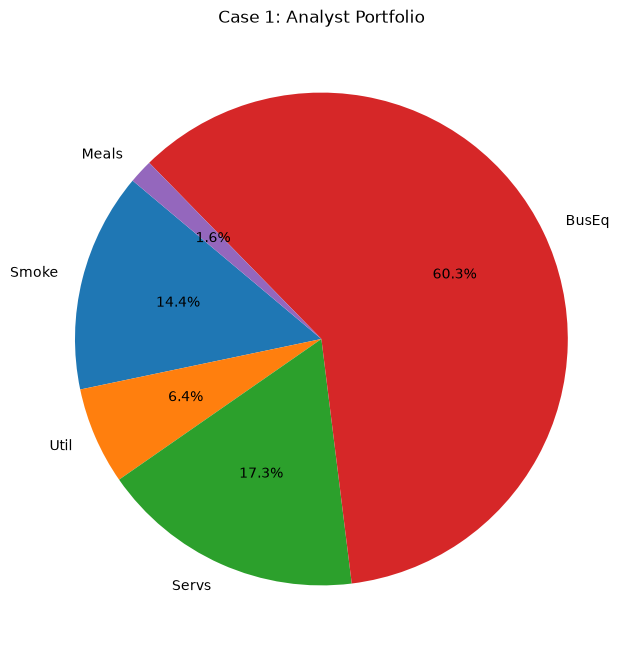

In [56]:
threshold = 0.0001
filtered_weightsa = [w for w in wa if w > threshold]
filtered_namesa = [names[i] for i, w in enumerate(wa) if w > threshold]

plt.figure(figsize=(8, 8))
# autopct='%1.1f%%' displays the percentage on the chart
plt.pie(filtered_weightsa, labels=filtered_namesa, autopct='%1.1f%%', startangle=140)
plt.title("Case 1: Analyst Portfolio")
plt.savefig("Analyst Portfolio Stocks (Max Vol)", dpi=300, bbox_inches='tight')
plt.show()

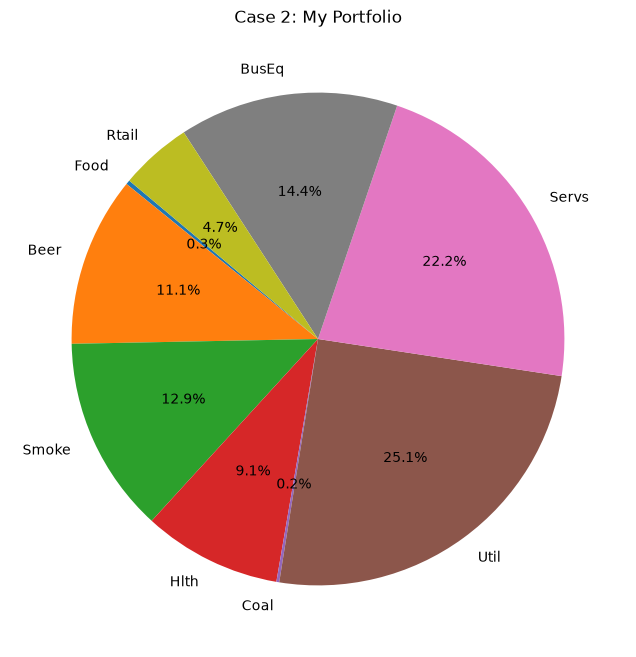

In [57]:
filtered_weightsb = [wtest for wtest in wtest1 if wtest > threshold]
filtered_namesb = [names[i] for i, wtest in enumerate(wtest1) if wtest > threshold]

plt.figure(figsize=(8, 8))
# autopct='%1.1f%%' displays the percentage on the chart
plt.pie(filtered_weightsb, labels=filtered_namesb, autopct='%1.1f%%', startangle=140)
plt.title("Case 2: My Portfolio")
plt.savefig("My Portfolio Stocks (Optimal Vol)", dpi=300, bbox_inches='tight')
plt.show()

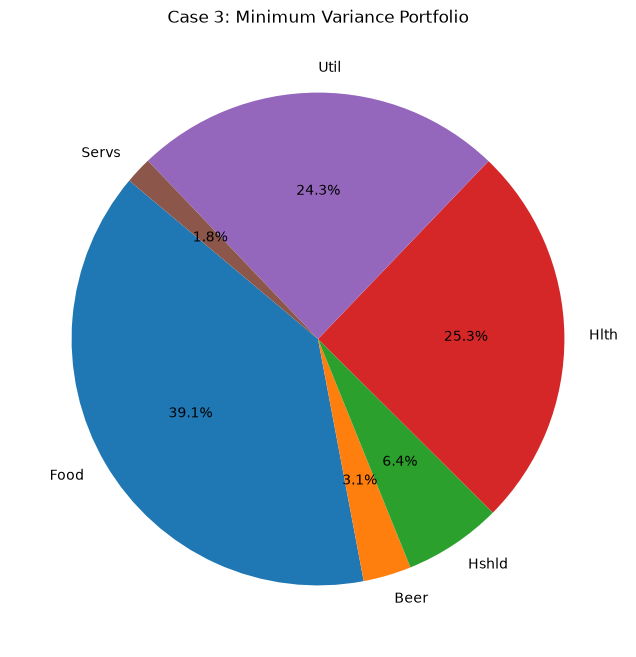

In [58]:
filtered_weightsc = [wtestb for wtestb in wtestb2 if wtestb > threshold]
filtered_namesc = [names[i] for i, wtestb in enumerate(wtestb2) if wtestb > threshold]

plt.figure(figsize=(8, 8))
# autopct='%1.1f%%' displays the percentage on the chart
plt.pie(filtered_weightsc, labels=filtered_namesc, autopct='%1.1f%%', startangle=140)
plt.title("Case 3: Minimum Variance Portfolio")
plt.savefig("Lowest Return Portfolio Stocks (Lowest Vol)", dpi=300, bbox_inches='tight')
plt.show()

I will also try the out of sample testing. I need to just compare the base model versus mine out of the sample. I will take the date from 01-2025 onwards to 08-2026 (as load_industries.py annualises it anyway). Could also do til 12-2025, but decide not to.

In [86]:
# firt we get the expected value and Sigma for this out of sample period
mu2, Sigma2, names2 = estimation_inputs(R, start="2025-01", end="2026-08")

# we then just use the weight vectors we have for the base and my problem, and apply them to the new mu and Sigma
baseretoos = (mu2 @ wa) *100
basevoloos = np.sqrt(wa @ Sigma2 @ wa) * 100

print("Base Annual Return OOS: ", baseretoos, "%")
print("Base Annual Volatility OOS: ", basevoloos, "%")


Base Annual Return OOS:  27.96007368008973 %
Base Annual Volatility OOS:  18.08738613166553 %


In [87]:
# we then just use the weight vectors we have for the base and my problem, and apply them to the new mu and Sigma
myretoos = (mu2 @ wtest1) *100
myvoloos = np.sqrt(wtest1 @ Sigma2 @ wtest1) * 100

print("My Annual Return OOS: ", myretoos, "%")
print("My Annual Volatility OOS: ", myvoloos, "%")

My Annual Return OOS:  16.690118353108083 %
My Annual Volatility OOS:  9.393387380205635 %


Compare the differences in out of smaple and in sample w.r.t. percent points.

In [88]:
baseretdiff = (baseretoos-returna)
basevoldiff = (basevoloos-volatilitya)

print("Difference in Base Performance INvsOUT: return = ", baseretdiff)
print("and volatility =", basevoldiff)

Difference in Base Performance INvsOUT: return =  8.727414738057064
and volatility = 0.7223955330616647


In [90]:
myretdiff = (myretoos-returntest)
myvoldiff = (myvoloos-volatilitytest)

print("Difference in My Performance INvsOUT: return = ", myretdiff)
print("and volatility =", myvoldiff)

Difference in My Performance INvsOUT: return =  3.309549206314303
and volatility = -3.946899297293868


Look at effective number of industries.

In [91]:
# effective number of industries for my problem
myeff = 1 / np.sum(wtest1 ** 2)

print(f"Recommended effective industries: {myeff:.2f}")

Recommended effective industries: 5.80
